# Week 10 — Fourier Theory & Parseval's Theorem in CT Image Formation

CT reconstruction is, at heart, a **Fourier** problem. This notebook builds the theory that connects
X-ray projections to the image:

1. The **Fourier transform** (1D and 2D) and what “k-space” means for an image.
2. **Parseval's / Plancherel's theorem** — energy is conserved between the spatial and frequency
   domains — and what that implies for signal energy, noise, and filtering.
3. The **Fourier Slice Theorem** (central-section theorem): the 1D Fourier transform of a projection
   at angle $\theta$ is a **radial line** through the 2D Fourier transform of the image at that angle.
   This is the exact bridge from **Radon space (sinogram)** to the image.
4. Why filling k-space with projection spokes forces the **ramp filter** used in filtered
   back-projection.

Together these explain *why* acquiring projections at many angles lets us invert to an image.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft, ifft2, fft2, fftshift, ifftshift, fftfreq
from skimage.data import shepp_logan_phantom
from skimage.transform import resize

rng = np.random.default_rng(0)
plt.rcParams["figure.dpi"] = 110

## 1. The Fourier transform: a signal and its spectrum

The Fourier transform rewrites a signal as a sum of sinusoids. The forward/inverse pair is
$$X(f)=\int x(t)\,e^{-i 2\pi f t}\,dt,\qquad x(t)=\int X(f)\,e^{+i 2\pi f t}\,df.$$
The **magnitude** $|X(f)|$ tells us how much of each frequency is present.

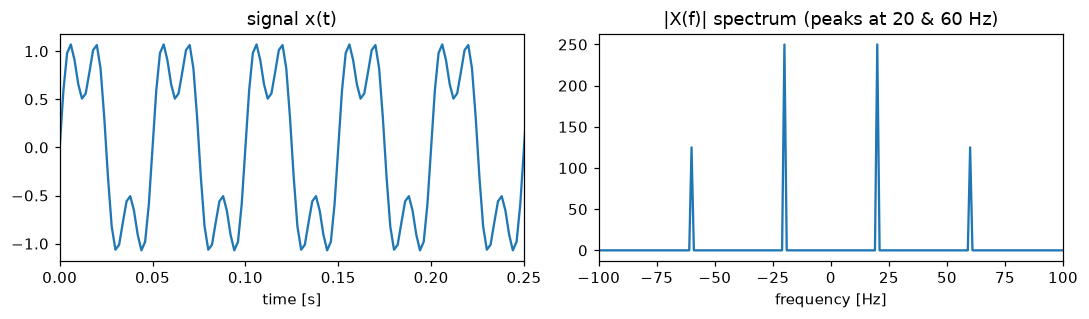

In [2]:
fs = 500                                   # sampling rate [Hz]
t = np.arange(0, 1, 1 / fs)
x = np.sin(2 * np.pi * 20 * t) + 0.5 * np.sin(2 * np.pi * 60 * t)   # 20 Hz + 60 Hz

X = fftshift(fft(x))
f = fftshift(fftfreq(len(t), 1 / fs))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(t, x); ax[0].set_xlabel("time [s]"); ax[0].set_title("signal x(t)"); ax[0].set_xlim(0, 0.25)
ax[1].plot(f, np.abs(X)); ax[1].set_xlim(-100, 100)
ax[1].set_xlabel("frequency [Hz]"); ax[1].set_title("|X(f)| spectrum (peaks at 20 & 60 Hz)")
plt.tight_layout(); plt.show()

## 2. Parseval's theorem: energy is conserved

**Parseval's / Plancherel's theorem** states that the total energy of a signal is the same whether
computed in the spatial/time domain or in the frequency domain:
$$\sum_{n} |x_n|^2 \;=\; \frac{1}{N}\sum_{k} |X_k|^2.$$
The $1/N$ is the normalization for NumPy's unnormalized DFT. Energy isn't created or destroyed by the
transform — it is only **redistributed** across frequencies. We verify it numerically below (the
relative error is at the level of floating-point round-off).

In [3]:
energy_time = np.sum(np.abs(x) ** 2)
energy_freq = np.sum(np.abs(fft(x)) ** 2) / len(x)
print(f"energy in time domain      = {energy_time:.4f}")
print(f"energy in frequency domain = {energy_freq:.4f}")
print(f"relative difference        = {abs(energy_time - energy_freq) / energy_time:.2e}")

energy in time domain      = 312.5000
energy in frequency domain = 312.5000
relative difference        = 1.82e-16


## 3. The 2D Fourier transform of an image = k-space

An image $f(x,y)$ has a 2D transform $F(k_x,k_y)$ — the same **k-space** idea you met in MRI. Low
frequencies (near the center) carry overall contrast and large structures; high frequencies (toward
the edges) carry fine detail and edges.

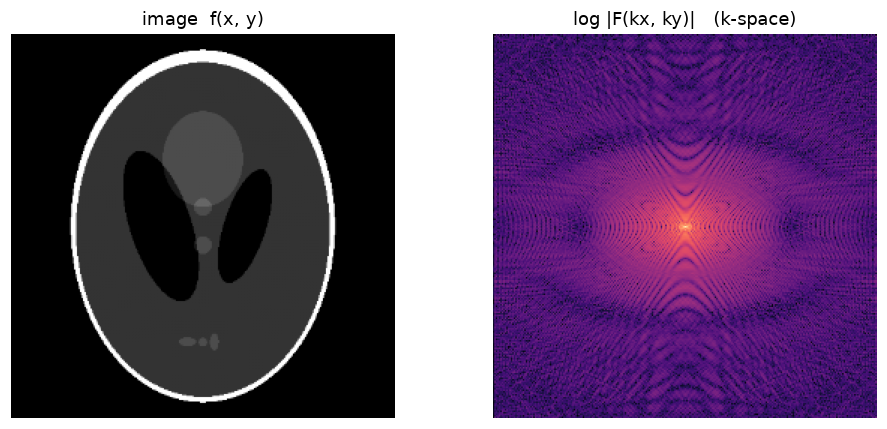

In [4]:
img = resize(shepp_logan_phantom(), (256, 256), anti_aliasing=True)
F = fftshift(fft2(img))

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("image  f(x, y)"); ax[0].axis("off")
ax[1].imshow(np.log1p(np.abs(F)), cmap="magma")
ax[1].set_title("log |F(kx, ky)|   (k-space)"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 4. Parseval in 2D: energy, noise, and filtering

The same conservation holds for images. This has real consequences:
- **Energy / dose / SNR**: the total energy of the measured signal is fixed; concentrating it in fewer
  frequencies (or acquiring more photons) improves signal-to-noise.
- **Filtering removes energy**: a **low-pass** filter (keep only a central disk of k-space) discards
  the high-frequency energy — we can read off *exactly how much* energy survives, and the image blurs
  accordingly. This is the frequency-domain view of smoothing/denoising and of limited resolution.

Parseval 2D relative error = 1.18e-16



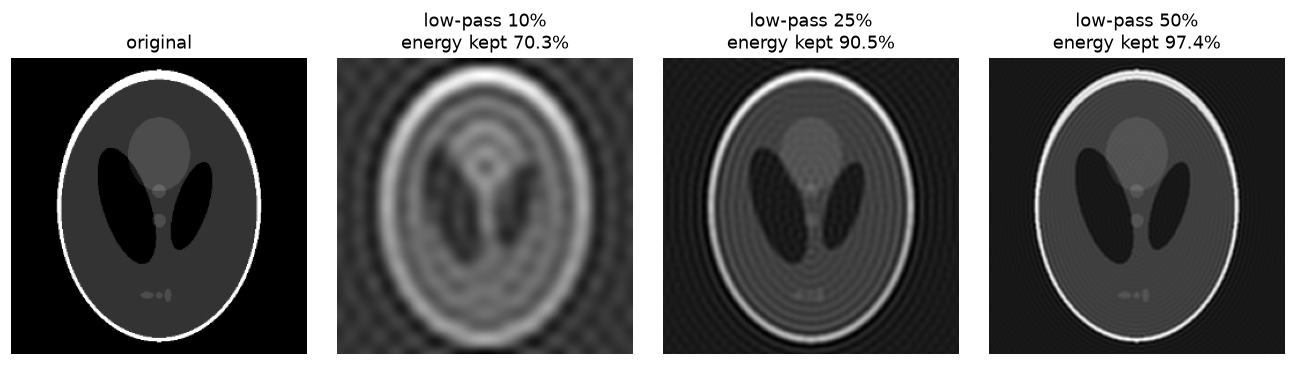

In [5]:
e_img = np.sum(np.abs(img) ** 2)
e_spec = np.sum(np.abs(fft2(img)) ** 2) / img.size
print(f"Parseval 2D relative error = {abs(e_img - e_spec) / e_img:.2e}\n")

N = img.shape[0]
Y, X = np.ogrid[:N, :N]
r = np.sqrt((X - N // 2) ** 2 + (Y - N // 2) ** 2)
total_spec_energy = np.sum(np.abs(F) ** 2)

fig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("original"); ax[0].axis("off")
for a, frac in zip(ax[1:], [0.10, 0.25, 0.50]):
    mask = r <= frac * (N / 2)
    F_lp = F * mask
    img_lp = np.real(ifft2(ifftshift(F_lp)))
    retained = np.sum(np.abs(F_lp) ** 2) / total_spec_energy
    a.imshow(img_lp, cmap="gray"); a.axis("off")
    a.set_title(f"low-pass {int(frac*100)}%\nenergy kept {retained*100:.1f}%")
plt.tight_layout(); plt.show()

## 5. The Fourier Slice Theorem — the heart of CT

A CT projection $p_\theta(s)$ is the **line integral** of the image along rays at angle $\theta$ (one
column of the sinogram). The **Fourier Slice Theorem** says:
$$\mathcal{F}_{1D}\{p_\theta\}(\omega) \;=\; F(\omega\cos\theta,\ \omega\sin\theta).$$
That is, the **1D Fourier transform of a projection** equals a **radial slice** through the image's
**2D Fourier transform** at the same angle. So each projection hands us one spoke of k-space; collect
enough angles and you fill k-space, then a single inverse 2D FFT returns the image.

We verify the two exact, axis-aligned cases. The $0^\circ$ projection is the sum over rows,
$p(x)=\sum_y f(x,y)$; its 1D FFT must equal the $k_y=0$ (central row) line of $F$. Likewise $90^\circ$
matches the central column.

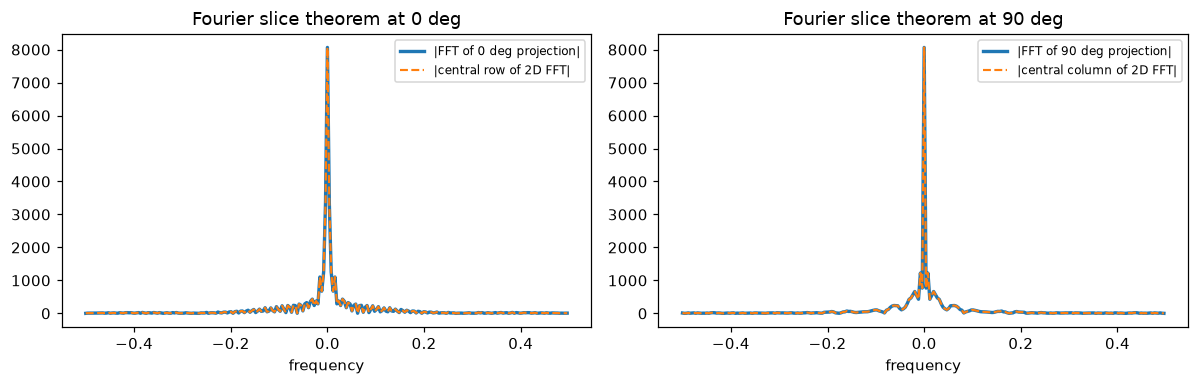

max relative diff  0 deg = 6.77e-16
max relative diff 90 deg = 1.13e-16


In [6]:
Fc = fftshift(fft2(ifftshift(img)))
k = fftshift(fftfreq(N))

p0 = img.sum(axis=0)                        # projection at 0 deg -> function of x
P0 = fftshift(fft(ifftshift(p0)))
slice0 = Fc[N // 2, :]                      # ky = 0 central row

p90 = img.sum(axis=1)                       # projection at 90 deg -> function of y
P90 = fftshift(fft(ifftshift(p90)))
slice90 = Fc[:, N // 2]                     # kx = 0 central column

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(k, np.abs(P0), lw=2.2, label="|FFT of 0 deg projection|")
ax[0].plot(k, np.abs(slice0), "--", lw=1.4, label="|central row of 2D FFT|")
ax[0].set_title("Fourier slice theorem at 0 deg"); ax[0].set_xlabel("frequency"); ax[0].legend(fontsize=8)
ax[1].plot(k, np.abs(P90), lw=2.2, label="|FFT of 90 deg projection|")
ax[1].plot(k, np.abs(slice90), "--", lw=1.4, label="|central column of 2D FFT|")
ax[1].set_title("Fourier slice theorem at 90 deg"); ax[1].set_xlabel("frequency"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"max relative diff  0 deg = {np.max(np.abs(np.abs(P0) - np.abs(slice0))) / np.max(np.abs(slice0)):.2e}")
print(f"max relative diff 90 deg = {np.max(np.abs(np.abs(P90) - np.abs(slice90))) / np.max(np.abs(slice90)):.2e}")

## 6. Filling k-space with spokes → why FBP needs a ramp filter

Each projection contributes a **radial spoke** to k-space. Stacking spokes from many angles samples
k-space in **polar** coordinates — which **oversamples the center**: the density of samples per unit
area grows like $1/|k|$. If we simply back-project, low frequencies are over-weighted and the image is
blurred. The fix in **filtered back-projection** is to multiply each projection's spectrum by the
**ramp filter** $|k|$, which exactly cancels the $1/|k|$ density — restoring a flat, Cartesian-like
weighting before the inverse transform.

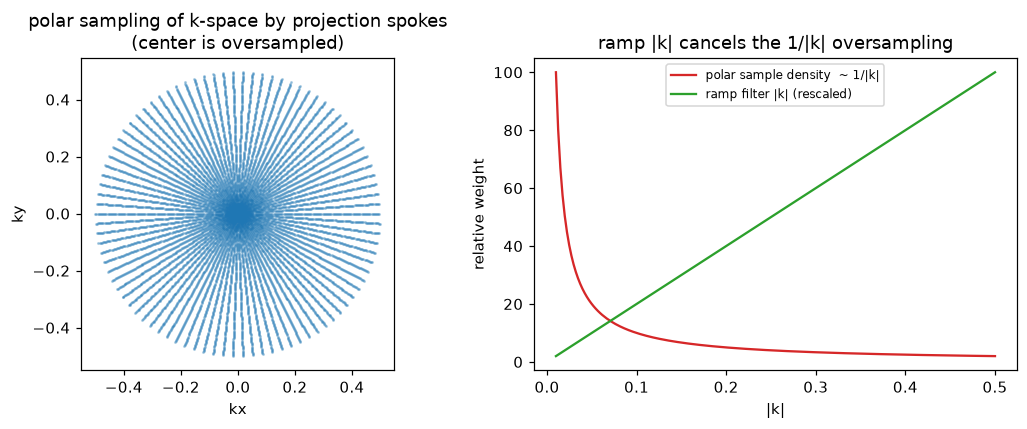

In [7]:
theta = np.deg2rad(np.arange(0, 180, 4))
freqs = fftshift(fftfreq(N))
kx = np.outer(freqs, np.cos(theta)).ravel()
ky = np.outer(freqs, np.sin(theta)).ravel()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(kx, ky, s=1, alpha=0.3, color="tab:blue")
ax[0].set_aspect("equal"); ax[0].set_xlabel("kx"); ax[0].set_ylabel("ky")
ax[0].set_title("polar sampling of k-space by projection spokes\n(center is oversampled)")

km = np.linspace(0.01, 0.5, 200)
ax[1].plot(km, 1 / km, label="polar sample density  ~ 1/|k|", color="tab:red")
ax[1].plot(km, km / km.max() * (1 / km).max(), label="ramp filter |k| (rescaled)", color="tab:green")
ax[1].set_xlabel("|k|"); ax[1].set_ylabel("relative weight")
ax[1].set_title("ramp |k| cancels the 1/|k| oversampling"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Takeaways

- The **Fourier transform** expresses a signal/image as frequencies; for an image this is **k-space**,
  center = low frequencies (contrast), edges = high frequencies (detail).
- **Parseval's theorem** conserves energy between domains (verified to round-off in 1D and 2D). It
  frames **SNR/dose** and makes **filtering** quantitative: a low-pass filter discards a measurable
  fraction of energy and blurs the image.
- The **Fourier Slice Theorem** is the exact link for CT: the 1D FFT of each projection is a **radial
  line** of the image's 2D FFT. Many angles → filled k-space → inverse 2D FFT → image.
- Projections sample k-space in **polar** form, oversampling the center ($\sim 1/|k|$); the **ramp
  filter** $|k|$ corrects this — the theoretical basis of **filtered back-projection**.
- The companion notebook, `ReconstructionMethods_Compare.ipynb`, turns this theory into three working
  reconstruction algorithms and compares them.